# What predicts the sign of an overnight jump, and what only predicts its size

An overnight jump is the move a market makes while it is shut,
$J_t = \log \mathrm{Open}_t - \log \mathrm{Close}_{t-1}$. `notebooks/overnight_jumps.ipynb`
establishes the awkward fact about it: over some 500 sessions each for nine instruments, a
Ljung-Box test rejects independence of the *signed* jump for none of them and of its *absolute
value* for all nine. Whatever is forecastable here is a magnitude.

That is a statement about the market's own history. This notebook asks what happens when the
search widens, and it asks it against the literature rather than against a screen of whatever
the data happens to hold: every column of the design comes from a published claim about
overnight returns, `jump.covariates.SOURCE` records which, and
`docs/overnight-jumps-literature.md` reads them together. The columns are

- the **closing fraction** of the previous session, `late`, which is where Boyarchenko, Larsen and
  Whelan [[17]](../docs/references.md#ref-boyarchenko-larsen-whelan-2023) find the order imbalance
  that the overnight drift compensates, and the window Gao, Han, Li and Zhou
  [[31]](../docs/references.md#ref-gao-etal-2018) and Xu et al.
  [[81]](../docs/references.md#ref-xu-etal-2025) use for intraday and cross-market momentum;
- the **opening fraction**, `early`, the other half of that pair;
- the session's **return**, `ret`, which is Lou, Polk and Skouras's
  [[58]](../docs/references.md#ref-lou-polk-skouras-2019) cross-period reversal term;
- where the close sat in the session's **range**, `close_loc`;
- **realised volatility** `rvol` and the Parkinson **range** `rng`;
- **signed jump variation** `sjv`, the difference of the two realised semivariances of
  Barndorff-Nielsen, Kinnebrock and Shephard
  [[8]](../docs/references.md#ref-barndorff-nielsen-kinnebrock-shephard-2010), which Patton and
  Sheppard [[66]](../docs/references.md#ref-patton-sheppard-2015) show carries information a return
  and a realised volatility both discard;
- **relative volume** `vol_rel`, standing in for the retail attention Berkman, Koch, Tuttle and
  Zhang [[11]](../docs/references.md#ref-berkman-etal-2012) find the effect concentrated in;
- the jump's own lag and its size, and how many calendar days the market was shut;
- and a **foreign session**, the London market, which trades through the New York night -- Hamao,
  Masulis and Ng's [[38]](../docs/references.md#ref-hamao-masulis-ng-1990) transmission --
  **truncated at 13:00 London**, before the New York open under either daylight-saving offset.

Every one of them was observable before the jump it is paired with. That is the part to get
right and the part nothing downstream would catch: a design carrying session $t$'s own
summaries against $J_t$ fits better than the correct one and is worthless.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from fts_research.core import style
from fts_research.fdaSP import intraday as itd
from fts_research.jump import covariates as cov

style.use(plt)
pd.set_option("display.width", 160)

SIGN, SIZE = style.CATEGORICAL[0], style.CATEGORICAL[1]
FOREIGN = "^FTSE"

## 1. The design, and its clock

`panel_design` builds one frame per instrument and stacks them. The London columns are
identical across instruments by construction -- one night's news reaches all of them -- which
is exactly the shared row that makes a random cross-validation split of this panel leak, and
the reason everything below splits on the date instead.

In [2]:
panel = cov.panel_design("1h", foreign_ticker=FOREIGN, until="13:00")
PRED = [c for c in panel.columns if c not in ("ticker", "session", "jump", "abs_jump")]

print(f"{panel['ticker'].nunique()} instruments, "
      f"{panel.groupby('ticker').size().min()} nights each, "
      f"{panel['session'].min()} to {panel['session'].max()}")
print(f"{len(PRED)} predictors: {PRED}")
print()
for name in PRED:
    print(f"  {name:<14} {cov.SOURCE[name]}")

8 instruments, 477 nights each, 2024-09-09 to 2026-08-28
13 predictors: ['ret', 'late', 'early', 'close_loc', 'rvol', 'sjv', 'rng', 'vol_rel', 'gap_days', 'jump_lag', 'abs_jump_lag', 'foreign_ret', 'foreign_rvol']

  ret            Lou, Polk & Skouras (2019): cross-period reversal
  late           Boyarchenko, Larsen & Whelan (2023): closing imbalance, absorbed overnight
  early          Gao, Han, Li & Zhou (2018): intraday momentum
  close_loc      closing pressure, as a position in the session's range
  rvol           realised volatility: the size of the session
  sjv            Patton & Sheppard (2015): signed jump variation
  rng            Parkinson (1980): the high-low range
  vol_rel        Berkman, Koch, Tuttle & Zhang (2012): attention, as abnormal volume
  gap_days       hours the market was shut, and so hours for news to arrive
  jump_lag       the equation's own AR(1) term
  abs_jump_lag   its size, which `overnight_jumps.ipynb` finds is the forecastable part
  foreign_ret 

foreign_ret takes 1 distinct value(s) per date across 8 instruments


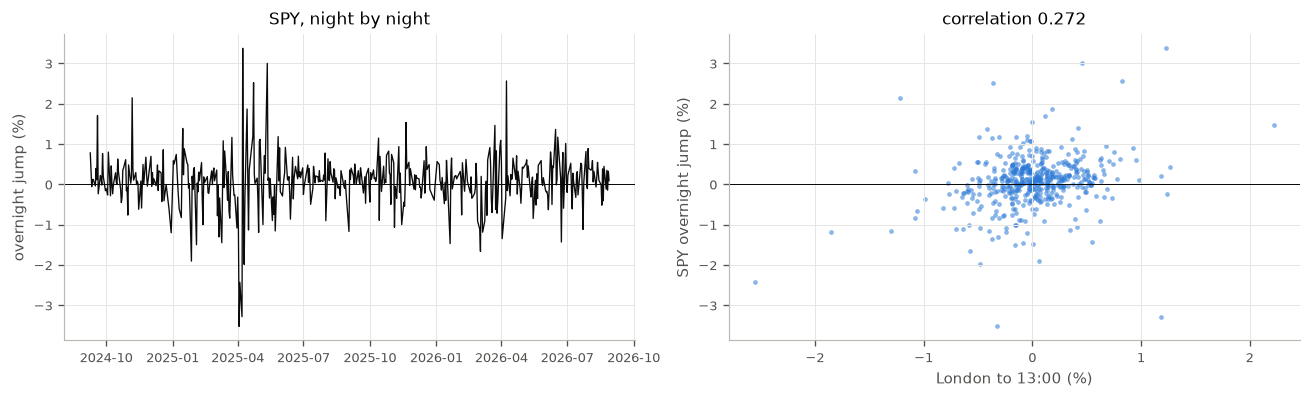

In [3]:
# The London session is one number a night, whatever it is paired with.
shared = panel.groupby("session")["foreign_ret"].nunique()
print(f"foreign_ret takes {shared.max()} distinct value(s) per date across "
      f"{panel['ticker'].nunique()} instruments")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
spy = panel[panel["ticker"] == "SPY"]
axes[0].plot(pd.to_datetime(spy["session"]), 100 * spy["jump"], lw=0.8, color=style.INK)
axes[0].set_ylabel("overnight jump (%)"); axes[0].set_title("SPY, night by night")
axes[1].scatter(100 * spy["foreign_ret"], 100 * spy["jump"], s=8, alpha=0.55, color=SIGN,
                lw=0)
axes[1].set_xlabel("London to 13:00 (%)"); axes[1].set_ylabel("SPY overnight jump (%)")
axes[1].set_title(f"correlation {np.corrcoef(spy['foreign_ret'], spy['jump'])[0, 1]:.3f}")
for ax in axes:
    ax.axhline(0, color=style.INK, lw=0.6)
fig.tight_layout()

## 2. A screen, corrected

Each predictor is run on its own against the signed jump and against its size, for every
instrument, with Newey-West standard errors. That is $2 \times$ instruments $\times$ predictors
tests, of which five per cent would clear the five per cent level with nothing there at all, so the
whole table goes through Benjamini and Hochberg's
[[10]](../docs/references.md#ref-benjamini-hochberg-1995) step-up procedure at once. What survives
is a candidate; what does not is not evidence of absence, and the two are not the same claim.

In [4]:
def hac_slope(y, x, lags=None):
    """One predictor, standardised, with Newey-West errors. Returns slope, t and p."""
    x = (x - x.mean()) / x.std()
    X = np.column_stack([np.ones(y.size), x])
    theta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ theta
    XtXi = np.linalg.inv(X.T @ X)
    n = y.size
    if lags is None:
        lags = int(np.floor(4.0 * (n / 100.0) ** (2.0 / 9.0)))
    u = X * resid[:, None]
    S = u.T @ u
    for lag in range(1, lags + 1):
        G = u[lag:].T @ u[:-lag]
        S = S + (1.0 - lag / (lags + 1.0)) * (G + G.T)
    se = float(np.sqrt(np.diag(XtXi @ S @ XtXi)[1]))
    t = float(theta[1] / se)
    return float(theta[1]), t, float(2.0 * stats.t.sf(abs(t), df=n - 2))


rows = []
for ticker, one in panel.groupby("ticker"):
    for target in ("jump", "abs_jump"):
        y = one[target].to_numpy(float)
        for name in PRED:
            beta, t, p = hac_slope(y, one[name].to_numpy(float))
            rows.append({"ticker": ticker, "target": target, "covariate": name,
                         "beta": beta, "t": t, "p": p})

screen = pd.DataFrame(rows)
bh = cov.benjamini_hochberg(screen["p"].to_numpy(), alpha=0.05)
screen["q"], screen["survives"] = bh["qvalues"], bh["reject"]
print(f"{len(screen)} tests, {bh['n_reject']} survive Benjamini-Hochberg at 5% "
      f"(p <= {bh['threshold']:.5f}); {int((screen['p'] <= 0.05).sum())} would clear an "
      f"uncorrected 5% level")

208 tests, 48 survive Benjamini-Hochberg at 5% (p <= 0.01086); 63 would clear an uncorrected 5% level


In [5]:
counts = (screen[screen["survives"]].groupby(["covariate", "target"]).size()
          .unstack(fill_value=0).reindex(PRED).fillna(0).astype(int))
counts.columns.name = None
counts = counts.rename(columns={"jump": "sign", "abs_jump": "size"})
counts["mean t (sign)"] = screen[screen["target"] == "jump"].groupby("covariate")["t"].mean()
counts["mean t (size)"] = (screen[screen["target"] == "abs_jump"]
                           .groupby("covariate")["t"].mean())
print("instruments (of 8) surviving the correction, and the mean t across all of them\n")
print(counts.round(2).to_string())

instruments (of 8) surviving the correction, and the mean t across all of them

              size  sign  mean t (sign)  mean t (size)
covariate                                             
ret              0     0          -0.30           0.43
late             0     0          -0.43          -0.06
early            0     0          -0.29           0.04
close_loc        3     0          -0.60          -1.51
rvol             8     0          -0.08           4.27
sjv              3     5          -3.01           2.30
rng              8     0           0.16           4.71
vol_rel          3     0           0.19           2.51
gap_days         6     0           0.53           2.52
jump_lag         0     0           0.69          -1.41
abs_jump_lag     2     0          -0.17           1.67
foreign_ret      0     5           3.39          -0.60
foreign_rvol     5     0          -1.47           3.16


The two columns are not the same picture, and the difference is the finding.

**The size is forecastable by almost everything.** The Parkinson range and realised volatility
survive for every instrument, the length of the closure for most, and the London session's own
realised volatility for most. That is the literature's settled half, and it is what
`overnight_jumps.ipynb` found from the market's own history alone.

**The sign survives for two things, and neither is the market's own return.** The truncated
London session, positively, and signed jump variation, negatively. The previous session's
return survives for no instrument, its closing fraction for none, its opening fraction for
none, and the jump's own lag for none.

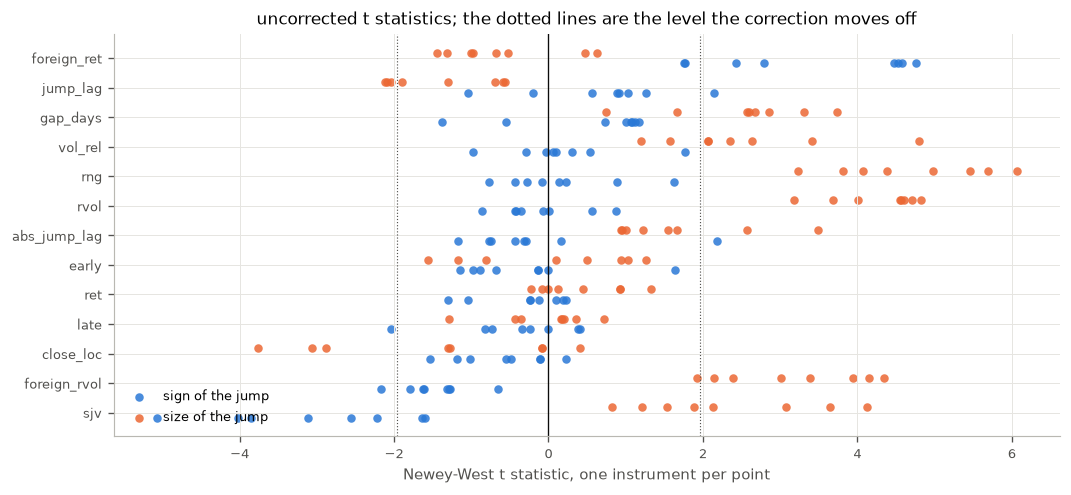

In [6]:
order = counts.sort_values("mean t (sign)").index
fig, ax = plt.subplots(figsize=(9, 4.2))
for target, colour, label, offset in (("jump", SIGN, "sign of the jump", -0.18),
                                      ("abs_jump", SIZE, "size of the jump", 0.18)):
    sub = screen[screen["target"] == target]
    for i, name in enumerate(order):
        here = sub[sub["covariate"] == name]
        ax.scatter(here["t"], np.full(len(here), i + offset), s=26,
                   color=colour, alpha=0.85, lw=0,
                   label=label if i == 0 else None)
ax.axvline(0, color=style.INK, lw=0.8)
for edge in (-1.96, 1.96):
    ax.axvline(edge, color=style.MUTED, lw=0.7, ls=":")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("Newey-West t statistic, one instrument per point")
ax.set_title("uncorrected t statistics; the dotted lines are the level the correction "
             "moves off")
ax.legend(loc="lower left", frameon=False)
fig.tight_layout()

## 3. What signed jump variation sees that a return does not

`sjv` is $RS^{+} - RS^{-}$, the upside minus the downside part of a session's realised
variance. Two sessions can end at the same price, with the same realised volatility, and have
opposite signed variation: one rose hard and gave it back, the other fell hard and recovered.
The screen says the second is followed by a *higher* overnight jump and the first by a lower
one, while the return itself -- which is the same for both -- says nothing.

That is a reversal, but not of the session's move. It is a reversal of the direction the
session's *variation* came from.

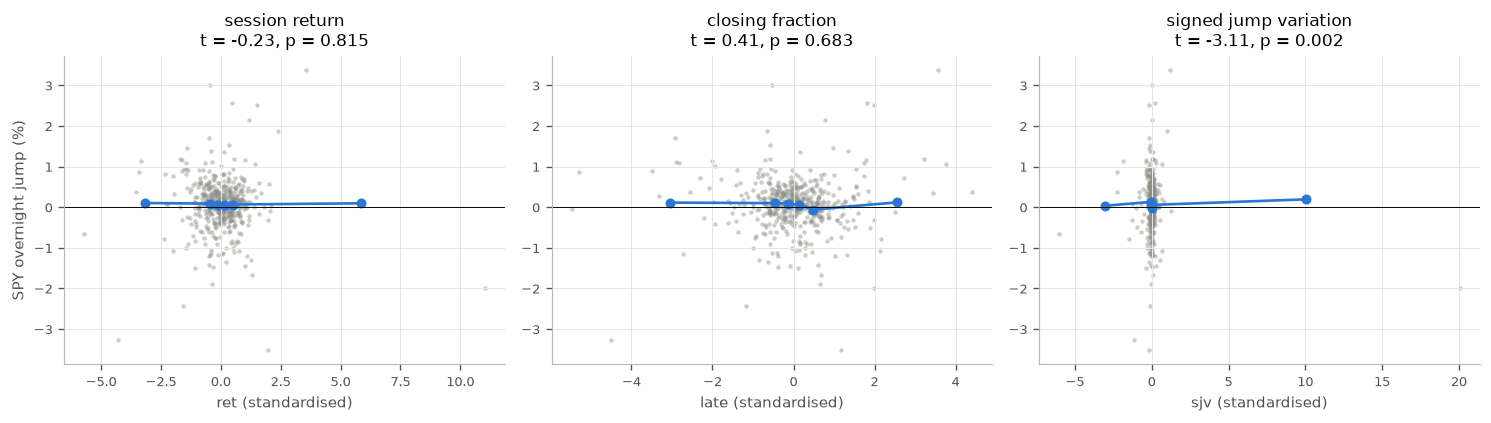

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
one = panel[panel["ticker"] == "SPY"]
for ax, name, title in zip(axes, ("ret", "late", "sjv"),
                           ("session return", "closing fraction",
                            "signed jump variation")):
    x = one[name].to_numpy(float)
    x = (x - x.mean()) / x.std()
    y = 100 * one["jump"].to_numpy(float)
    ax.scatter(x, y, s=7, alpha=0.45, color=style.CONTROL, lw=0)
    edges = np.quantile(x, np.linspace(0, 1, 7))
    mid = 0.5 * (edges[:-1] + edges[1:])
    binned = [y[(x >= lo) & (x < hi)].mean() for lo, hi in zip(edges[:-1], edges[1:])]
    ax.plot(mid, binned, "o-", color=SIGN, lw=1.6, ms=5)
    ax.axhline(0, color=style.INK, lw=0.6)
    beta, t, p = hac_slope(one["jump"].to_numpy(float), one[name].to_numpy(float))
    ax.set_title(f"{title}\nt = {t:.2f}, p = {p:.3f}")
    ax.set_xlabel(f"{name} (standardised)")
axes[0].set_ylabel("SPY overnight jump (%)")
fig.tight_layout()

## 4. Out of sample, on date-blocked folds

An in-sample $t$ statistic on 477 nights is not a forecast. Every fit below is scored on
held-out blocks of consecutive dates, against the mean of the training block, so the
$R^2$ is the out-of-sample kind and can be negative -- which for the sign of an overnight jump
it usually is.

In [8]:
def blocked_r2(frame, names, target, n_folds=10):
    """Out-of-sample R-squared and hit rate on contiguous date blocks."""
    y = frame[target].to_numpy(float)
    X = np.column_stack([np.ones(y.size), frame[names].to_numpy(float)])
    folds = itd.date_blocked_folds(frame["session"].to_numpy(), n_folds)
    pred, base = np.empty_like(y), np.empty_like(y)
    for f in np.unique(folds):
        te, tr = folds == f, folds != f
        theta, *_ = np.linalg.lstsq(X[tr], y[tr], rcond=None)
        pred[te], base[te] = X[te] @ theta, y[tr].mean()
    r2 = 1.0 - np.sum((y - pred) ** 2) / np.sum((y - base) ** 2)
    hit = float(np.mean(np.sign(pred - base) == np.sign(y - base)))
    return r2, hit


SETS = {"foreign_ret": ["foreign_ret"], "sjv": ["sjv"],
        "both": ["foreign_ret", "sjv"],
        "both + own lag": ["foreign_ret", "sjv", "jump_lag"],
        "size: rvol, rng, gap, foreign_rvol": ["rvol", "rng", "gap_days", "foreign_rvol"]}

rows = []
for ticker, one in panel.groupby("ticker"):
    row = {"ticker": ticker}
    for label, names in SETS.items():
        target = "abs_jump" if label.startswith("size") else "jump"
        r2, hit = blocked_r2(one, names, target)
        row[label] = r2
        if label == "both":
            row["hit rate"] = hit
    rows.append(row)
oos = pd.DataFrame(rows).set_index("ticker")
print(oos.round(4).to_string())
print()
print(f"median out-of-sample R2 on the sign, both predictors: {oos['both'].median():.4f}, "
      f"positive on {int((oos['both'] > 0).sum())} of {len(oos)}")
print(f"median hit rate: {oos['hit rate'].median():.4f}")
print(f"median out-of-sample R2 on the size: "
      f"{oos['size: rvol, rng, gap, foreign_rvol'].median():.4f}")

        foreign_ret     sjv    both  hit rate  both + own lag  size: rvol, rng, gap, foreign_rvol
ticker                                                                                           
AAPL         0.0213 -0.0440 -0.0210    0.5367         -0.0179                              0.1171
AMZN         0.0107  0.0063  0.0163    0.5430          0.0329                              0.0766
MSFT        -0.0013 -0.0005 -0.0016    0.5597         -0.0023                              0.0306
NVDA         0.0230  0.0037  0.0276    0.5597          0.0225                              0.0746
QQQ          0.0443  0.0091  0.0529    0.5807          0.0469                              0.1533
SPY          0.0548  0.0102  0.0637    0.5786          0.0654                              0.2434
TSLA         0.0003  0.0103  0.0105    0.5304          0.0078                              0.0755
^GSPC        0.0482  0.0122  0.0572    0.5849          0.0557                              0.2048

median out-of-sampl

The ordering is the one the screen predicted and the magnitudes are the ones to quote. The
sign is forecastable, but barely, and only through the foreign session; the size is
forecastable several times over. Adding the jump's own lag to the two survivors
moves nothing, which is `overnight_jumps.ipynb`'s finding arriving a second way.

The three broad-market instruments do best on the sign and the single stocks worst, which is
what a news-transmission account predicts and an instrument-specific one does not: the London
session prices the part of the news that is common.

## 5. The truncation is not a compliance rule

The London session is cut at 13:00 because a market that closes at 16:30 London closes two hours
*after* New York opens, and a same-day foreign return taken whole is a look-ahead into most of the
session it is being used to forecast the start of. That is the flaw separating the
overnight-direction accuracies reported in the machine learning literature from those in finance:
Gao et al. [[32]](../docs/references.md#ref-gao-etal-2022) report 0.69 accuracy for the S&P 500
against 0.52 without international indices, using "the current returns of stock markets that open
before the target market on the same trading day" -- which for an American target includes European
markets that close four and a half hours after the New York open.

The measurement below is the interesting part. Truncating does not merely make the predictor
legitimate; it makes it **better**.

In [9]:
bars = itd.load_bars("1h")
rows = []
for label, until in (("cut at 13:00 London", "13:00"), ("whole London session", None)):
    london = cov.foreign_covariates(bars[bars["ticker"] == FOREIGN], until=until)
    for ticker in [t for t in itd.TICKERS if t != FOREIGN]:
        one = cov.jump_design(bars[bars["ticker"] == ticker],
                              foreign=london).reset_index()
        r2, hit = blocked_r2(one, ["foreign_ret"], "jump")
        rows.append({"foreign session": label, "ticker": ticker,
                     "corr": np.corrcoef(one["foreign_ret"], one["jump"])[0, 1],
                     "R2": r2, "hit": hit})
cut = pd.DataFrame(rows).pivot(index="ticker", columns="foreign session",
                               values=["corr", "R2"])
print(cut.round(4).to_string())
print()
for label in ("cut at 13:00 London", "whole London session"):
    sub = pd.DataFrame(rows).query("`foreign session` == @label")
    print(f"{label:<22} median corr {sub['corr'].median():.4f}, "
          f"median R2 {sub['R2'].median():.4f}, "
          f"positive R2 on {int((sub['R2'] > 0).sum())} of {len(sub)}")

                               corr                                       R2                     
foreign session cut at 13:00 London whole London session cut at 13:00 London whole London session
ticker                                                                                           
AAPL                         0.1630               0.1740              0.0213               0.0140
AMZN                         0.1551               0.0750              0.0107              -0.0191
MSFT                         0.0808               0.0250             -0.0013              -0.0164
NVDA                         0.1693               0.0555              0.0230              -0.0082
QQQ                          0.2380               0.1047              0.0443              -0.0124
SPY                          0.2723               0.1468              0.0548              -0.0075
TSLA                         0.1003               0.0105              0.0003              -0.0152
^GSPC               

The whole session contains the truncated one and predicts worse. There is no paradox: the
London afternoon overlaps the New York session, so it *responds to* the move that follows the
open rather than predicting the open, and adding it dilutes a real signal with variance that
carries none of it.

Which is to say that the truncation is doing the work of an estimator. That is the whole
argument for `truncFLR` and `fdaSP`, arriving from the data rather than from a paper -- and it
raises the question those packages exist to answer, which is *where* the cut belongs. Thirteen
hundred hours is a convention. `notebooks/region_selection.ipynb` puts the whole London curve
in as a functional regressor and lets the data choose the informative region under an error
bound, with a known answer to be scored against: the New York opening bell.

London session on the normalised domain:
  08:00=0.00  09:00=0.12  10:00=0.25  11:00=0.37  12:00=0.50  13:00=0.63  14:00=0.75  15:00=0.88  16:00=1.00
  New York opens at 14:30 or 13:30 London, i.e. s = 0.81 or s = 0.69


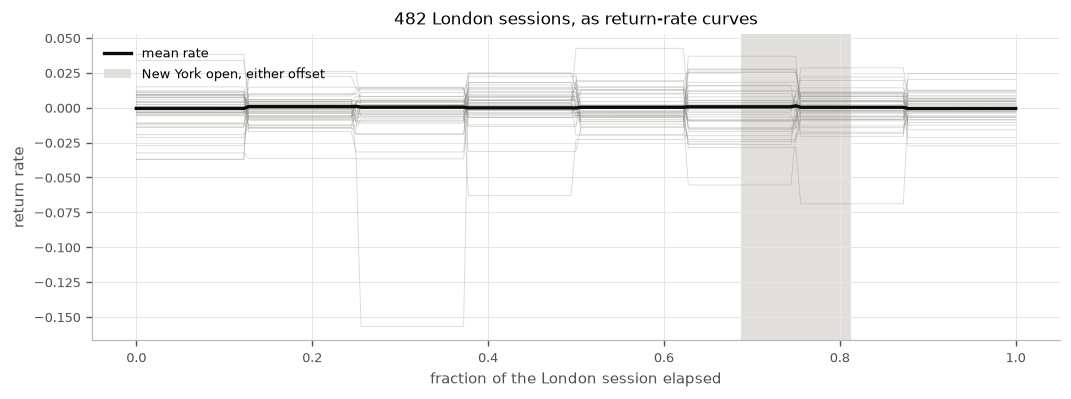

In [10]:
X, grid, dates = itd.session_curves(bars[bars["ticker"] == FOREIGN], kind="ret")
jumps = itd.overnight_jumps(bars[bars["ticker"] == "SPY"])
Xa, ya, when = itd.align_curves_to_series(X, dates, jumps["jump"], offset=0)

# Where each wall-clock hour of the London session sits on the normalised domain.
day = itd.sessions(bars[bars["ticker"] == FOREIGN])[-2]
clock = day["ts"].dt.strftime("%H:%M").tolist()
seconds = day["ts"].astype("int64").to_numpy() / 1e9
where = (seconds - seconds[0]) / (seconds[-1] - seconds[0])
print("London session on the normalised domain:")
print("  " + "  ".join(f"{t}={s:.2f}" for t, s in zip(clock, where)))
print("  New York opens at 14:30 or 13:30 London, i.e. s = 0.81 or s = 0.69")

fig, ax = plt.subplots(figsize=(9, 3.4))
for row in Xa[::12]:
    ax.plot(grid, row, lw=0.5, alpha=0.35, color=style.CONTROL)
ax.plot(grid, Xa.mean(axis=0), lw=2.0, color=style.INK, label="mean rate")
ax.axvspan(0.6875, 0.8125, color=style.BAND, alpha=0.8, lw=0,
           label="New York open, either offset")
ax.set_xlabel("fraction of the London session elapsed")
ax.set_ylabel("return rate")
ax.set_title(f"{len(ya)} London sessions, as return-rate curves")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()

## What this notebook found

**The sign of an overnight jump survives a corrected screen for exactly two predictors, and
neither is the market's own return.** Over 208 tests on eight instruments and 477 nights, the
London session truncated before the New York open survives for five of eight instruments and
signed jump variation for five of eight. The previous session's return, its closing fraction,
its opening fraction and the jump's own lag survive for none.

**What reverses overnight is the direction of the previous session's variation, not its
return.** Signed jump variation enters negatively while the return itself does not enter at
all, and the two are different summaries of the same session: a day that rose hard and gave it
back has the return of one that fell hard and recovered, and the opposite signed variation.

**The closing-imbalance channel does not appear in these panels.** Neither the closing return nor
the close's position in the session's range predicts the sign for any instrument. An hourly bar is
a poor proxy for a signed order imbalance, and the window here is 2024 to 2026, over which
Boyarchenko, Larsen and Whelan [[18]](../docs/references.md#ref-boyarchenko-larsen-whelan-2026)
report the imbalance channel itself as having closed -- the standard deviation of end-of-day
imbalances falling by more than half since 2021, and the drift with it.

**Truncating the foreign session before the domestic open improves the forecast rather than
merely legitimising it.** Correlation with the SPY jump is 0.27 for the London session cut at
13:00 against 0.15 for the whole of it, and the median out-of-sample $R^2$ across eight
instruments is positive for the cut version and negative for the whole one. The afternoon
responds to the session it is supposed to be forecasting.

**The size remains far more forecastable than the sign, by every measure here.** Realised
volatility and the range survive for all eight instruments where nothing survives for the sign
on more than five, and the held-out $R^2$ on the size is more than four times larger.